In [2]:
# --- Section 1: Setup, mixed precision & config ---
import os, glob, numpy as np, pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, models, mixed_precision
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications.efficientnet import preprocess_input
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# ⚡ Mixed precision = faster training on the GPU
mixed_precision.set_global_policy('mixed_float16')

RANDOM_STATE = 42
tf.random.set_seed(RANDOM_STATE); np.random.seed(RANDOM_STATE)

TARGET_CLASSES = ['angry', 'happy', 'sad', 'neutral']   # RAF-DB: 6->angry,4->happy,5->sad,7->neutral
IMG_SIZE = 224
BATCH    = 32
AUTOTUNE = tf.data.AUTOTUNE

print("TF:", tf.__version__, "| compute dtype:", mixed_precision.global_policy().compute_dtype)
gpus = tf.config.list_physical_devices('GPU')
print("GPU:", gpus[0].name if gpus else "❌ NONE — enable T4 GPU then re-run")

TF: 2.21.0 | compute dtype: float16
GPU: /physical_device:GPU:0


In [3]:
# --- Section 2a: Download RAF-DB ---
from google.colab import files
print("Upload your kaggle.json again...")
files.upload()
!mkdir -p ~/.kaggle && cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json

!kaggle datasets download -d shuvoalok/raf-db-dataset -q
!unzip -q -o raf-db-dataset.zip -d rafdb_data
print("Unzipped ✓")

Upload your kaggle.json again...


Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/shuvoalok/raf-db-dataset
License(s): other
Unzipped ✓


In [4]:
# --- Section 2b: Locate folders + class counts ---
root = 'rafdb_data'
cands = [dp for dp, dn, _ in os.walk(root) if {'4','5','6','7'}.issubset(set(dn))]
print("Folders containing class subfolders:")
for c in cands: print("  ", c)

TRAIN_DIR = next((c for c in cands if 'train' in c.lower()), None)
TEST_DIR  = next((c for c in cands if 'test'  in c.lower()), None)
print("\nTRAIN_DIR:", TRAIN_DIR, "\nTEST_DIR :", TEST_DIR)

# RAF-DB index -> our class.  4=happy, 5=sad, 6=angry, 7=neutral
rafdb_to_name = {'6':'angry', '4':'happy', '5':'sad', '7':'neutral'}
print("\nTrain counts (our 4 classes):")
for idx, nm in rafdb_to_name.items():
    print(f"  {nm:8s} (folder {idx}): {len(glob.glob(os.path.join(TRAIN_DIR, idx, '*')))}")

Folders containing class subfolders:
   rafdb_data/DATASET/train
   rafdb_data/DATASET/test

TRAIN_DIR: rafdb_data/DATASET/train 
TEST_DIR : rafdb_data/DATASET/test

Train counts (our 4 classes):
  angry    (folder 6): 705
  happy    (folder 4): 4772
  sad      (folder 5): 1982
  neutral  (folder 7): 2524


In [5]:
# --- Section 3: Build file lists + stratified split ---
from sklearn.model_selection import train_test_split

rafdb_to_label = {'6': 0, '4': 1, '5': 2, '7': 3}   # angry, happy, sad, neutral

def collect(split_dir):
    paths, labels = [], []
    for idx, lab in rafdb_to_label.items():
        for p in glob.glob(os.path.join(split_dir, idx, '*')):
            paths.append(p); labels.append(lab)
    return np.array(paths), np.array(labels)

train_paths_all, train_labels_all = collect(TRAIN_DIR)
test_paths, test_labels           = collect(TEST_DIR)

# stratified validation split from TRAIN (test stays pristine)
train_paths, val_paths, train_labels, val_labels = train_test_split(
    train_paths_all, train_labels_all, test_size=0.15,
    stratify=train_labels_all, random_state=RANDOM_STATE)

names = {0:'angry', 1:'happy', 2:'sad', 3:'neutral'}
print("Train:", len(train_paths), "| Val:", len(val_paths), "| Test:", len(test_paths))
print("\nTrain class distribution:")
print(pd.Series(train_labels).map(names).value_counts())
assert set(np.unique(train_labels)) == {0,1,2,3}, "A class is missing!"
print("All 4 classes present ✓")

Train: 8485 | Val: 1498 | Test: 2505

Train class distribution:
happy      4056
neutral    2145
sad        1685
angry       599
Name: count, dtype: int64
All 4 classes present ✓


In [6]:
# --- Section 4a: Professional preprocessing (resize + CLAHE + cache) ---
import cv2

def clahe_rgb(img_u8):
    """Illumination normalization via CLAHE on the L channel (keeps color)."""
    try:
        lab = cv2.cvtColor(img_u8, cv2.COLOR_RGB2LAB)
        l, a, b = cv2.split(lab)
        l = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(l)
        return cv2.cvtColor(cv2.merge((l, a, b)), cv2.COLOR_LAB2RGB)
    except Exception:
        return img_u8                       # graceful fallback

def load_u8(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.cast(tf.image.resize(img, [IMG_SIZE, IMG_SIZE]), tf.uint8)
    img = tf.py_function(lambda x: clahe_rgb(x.numpy()), [img], tf.uint8)   # CLAHE
    img.set_shape([IMG_SIZE, IMG_SIZE, 3])
    return img, label

def make_ds(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(load_u8, num_parallel_calls=AUTOTUNE).cache()     # CLAHE computed ONCE, then cached
    if training: ds = ds.shuffle(len(paths), seed=RANDOM_STATE)
    ds = ds.map(lambda x, y: (tf.cast(x, tf.float32), y), num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH).prefetch(AUTOTUNE)

train_ds = make_ds(train_paths, train_labels, training=True)
val_ds   = make_ds(val_paths,   val_labels)
test_ds  = make_ds(test_paths,  test_labels)
print("Professional pipeline ready: resize → CLAHE → cache.")

Professional pipeline ready: resize → CLAHE → cache.


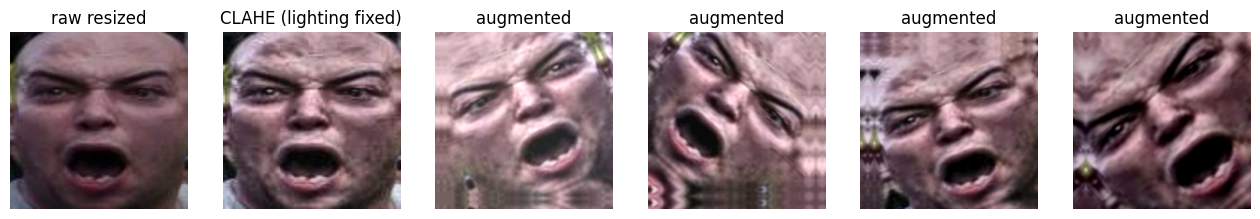

In [7]:
# --- Section 4b: Professional augmentation + visualize raw -> CLAHE -> augmented ---
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.12),
    layers.RandomZoom(0.12),
    layers.RandomTranslation(0.08, 0.08),
    layers.RandomContrast(0.15),
    layers.RandomBrightness(0.15, value_range=(0, 255)),
], name='augment')

raw = tf.cast(tf.image.resize(tf.image.decode_image(tf.io.read_file(train_paths[0]),
      channels=3, expand_animations=False), [IMG_SIZE, IMG_SIZE]), tf.uint8).numpy()
clahe_img = clahe_rgb(raw)
fig, ax = plt.subplots(1, 6, figsize=(16, 3))
ax[0].imshow(raw);       ax[0].set_title('raw resized');  ax[0].axis('off')
ax[1].imshow(clahe_img); ax[1].set_title('CLAHE (lighting fixed)'); ax[1].axis('off')
for i in range(2, 6):
    aug = data_augmentation(tf.expand_dims(tf.cast(clahe_img, tf.float32), 0), training=True)[0]
    ax[i].imshow(tf.clip_by_value(aug, 0, 255).numpy().astype('uint8')); ax[i].set_title('augmented'); ax[i].axis('off')
plt.show()

In [8]:
# --- Section 4c: Class weights ---
from sklearn.utils.class_weight import compute_class_weight
cw = compute_class_weight('balanced', classes=np.array([0,1,2,3]), y=train_labels)
class_weight = {i: float(w) for i, w in enumerate(cw)}
print("Class weights:", {names[i]: round(class_weight[i], 2) for i in range(4)})

Class weights: {'angry': 3.54, 'happy': 0.52, 'sad': 1.26, 'neutral': 0.99}


In [9]:
# --- Section 5: Build EfficientNetB0 transfer-learning model ---
base = EfficientNetB0(input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights='imagenet')
base.trainable = False      # Phase 1: freeze the pretrained body

inputs  = layers.Input((IMG_SIZE, IMG_SIZE, 3))
x = data_augmentation(inputs)                 # augment (train only)
x = base(x, training=False)                   # EfficientNet normalizes internally
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(len(TARGET_CLASSES), activation='softmax', dtype='float32')(x)  # float32 output (mixed precision)

model = models.Model(inputs, outputs)
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augment (Sequential)            │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,054,695 (15.47 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [10]:
# --- Section 6: Phase 1 training (frozen base) ---
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

cb = [
    EarlyStopping(monitor='val_accuracy', patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, verbose=1),
    ModelCheckpoint('best_effnet.keras', monitor='val_accuracy', save_best_only=True),
]

history1 = model.fit(train_ds, validation_data=val_ds,
                     epochs=15, class_weight=class_weight, callbacks=cb)
print("Phase 1 best val_accuracy:", max(history1.history['val_accuracy']))

Epoch 1/15
266/266 ━━━━━━━━━━━━━━━━━━━━ 76s 118ms/step - accuracy: 0.4442 - loss: 1.2512 - val_accuracy: 0.5047 - val_loss: 1.1571 - learning_rate: 0.0010
Epoch 2/15
266/266 ━━━━━━━━━━━━━━━━━━━━ 22s 83ms/step - accuracy: 0.5347 - loss: 1.1189 - val_accuracy: 0.5975 - val_loss: 1.0359 - learning_rate: 0.0010
Epoch 3/15
266/266 ━━━━━━━━━━━━━━━━━━━━ 21s 80ms/step - accuracy: 0.5507 - loss: 1.0778 - val_accuracy: 0.5888 - val_loss: 1.0146 - learning_rate: 0.0010
Epoch 4/15
266/266 ━━━━━━━━━━━━━━━━━━━━ 21s 79ms/step - accuracy: 0.5626 - loss: 1.0606 - val_accuracy: 0.5975 - val_loss: 0.9956 - learning_rate: 0.0010
Epoch 5/15
266/266 ━━━━━━━━━━━━━━━━━━━━ 22s 83ms/step - accuracy: 0.5741 - loss: 1.0324 - val_accuracy: 0.6395 - val_loss: 0.9465 - learning_rate: 0.0010
Epoch 6/15
266/266 ━━━━━━━━━━━━━━━━━━━━ 24s 89ms/step - accuracy: 0.5704 - loss: 1.0146 - val_accuracy: 0.6041 - val_loss: 0.9933 - learning_rate: 0.0010
Epoch 7/15
266/266 ━━━━━━━━━━━━━━━━━━━━ 21s 80ms/step - accuracy: 0.5834 - 

In [11]:
# --- Section 7: Phase 2 fine-tuning ---
base.trainable = True
for layer in base.layers:                       # EfficientNet best practice: keep BatchNorm frozen
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(optimizer=tf.keras.optimizers.Adam(1e-4),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])

cb2 = [
    EarlyStopping(monitor='val_accuracy', patience=7, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, verbose=1),
    ModelCheckpoint('best_effnet.keras', monitor='val_accuracy', save_best_only=True),
]

history2 = model.fit(train_ds, validation_data=val_ds,
                     epochs=25, class_weight=class_weight, callbacks=cb2)
print("Phase 2 best val_accuracy:", max(history2.history['val_accuracy']))

Epoch 1/25
266/266 ━━━━━━━━━━━━━━━━━━━━ 121s 274ms/step - accuracy: 0.6593 - loss: 0.8498 - val_accuracy: 0.7830 - val_loss: 0.5576 - learning_rate: 1.0000e-04
Epoch 2/25
266/266 ━━━━━━━━━━━━━━━━━━━━ 49s 184ms/step - accuracy: 0.7545 - loss: 0.6282 - val_accuracy: 0.7517 - val_loss: 0.6166 - learning_rate: 1.0000e-04
Epoch 3/25
266/266 ━━━━━━━━━━━━━━━━━━━━ 51s 190ms/step - accuracy: 0.7933 - loss: 0.5388 - val_accuracy: 0.7837 - val_loss: 0.5533 - learning_rate: 1.0000e-04
Epoch 4/25
266/266 ━━━━━━━━━━━━━━━━━━━━ 51s 192ms/step - accuracy: 0.8190 - loss: 0.4693 - val_accuracy: 0.7991 - val_loss: 0.5021 - learning_rate: 1.0000e-04
Epoch 5/25
266/266 ━━━━━━━━━━━━━━━━━━━━ 53s 200ms/step - accuracy: 0.8376 - loss: 0.4092 - val_accuracy: 0.8084 - val_loss: 0.5185 - learning_rate: 1.0000e-04
Epoch 6/25
266/266 ━━━━━━━━━━━━━━━━━━━━ 51s 192ms/step - accuracy: 0.8444 - loss: 0.3862 - val_accuracy: 0.8371 - val_loss: 0.4231 - learning_rate: 1.0000e-04
Epoch 7/25
266/266 ━━━━━━━━━━━━━━━━━━━━ 50s 1

In [12]:
# --- Optimized model (more dropout) ---
base = EfficientNetB0(input_shape=(IMG_SIZE,IMG_SIZE,3), include_top=False, weights='imagenet')
base.trainable = False
inputs  = layers.Input((IMG_SIZE,IMG_SIZE,3))
x = data_augmentation(inputs)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.5)(x)                                    # ↑ stronger dropout
outputs = layers.Dense(len(TARGET_CLASSES), activation='softmax', dtype='float32')(x)
model = models.Model(inputs, outputs)
print("Rebuilt with dropout 0.5")

Rebuilt with dropout 0.5


In [13]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Phase 1: train head
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.fit(train_ds, validation_data=val_ds, epochs=6, class_weight=class_weight,
          callbacks=[EarlyStopping(monitor='val_accuracy', patience=4, restore_best_weights=True)])

# Phase 2: fine-tune with AdamW (weight decay) + cosine LR
base.trainable = True
for l in base.layers:
    if isinstance(l, layers.BatchNormalization): l.trainable = False

steps  = len(train_paths)//BATCH
cosine = tf.keras.optimizers.schedules.CosineDecay(1e-4, decay_steps=steps*25)
model.compile(optimizer=tf.keras.optimizers.AdamW(learning_rate=cosine, weight_decay=1e-4),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])

cb2 = [EarlyStopping(monitor='val_accuracy', patience=8, restore_best_weights=True),
       ModelCheckpoint('best_effnet.keras', monitor='val_accuracy', save_best_only=True)]
h = model.fit(train_ds, validation_data=val_ds, epochs=30, class_weight=class_weight, callbacks=cb2)
print("Optimized best val_accuracy:", max(h.history['val_accuracy']))

Epoch 1/6
266/266 ━━━━━━━━━━━━━━━━━━━━ 45s 91ms/step - accuracy: 0.4181 - loss: 1.2963 - val_accuracy: 0.5621 - val_loss: 1.0965
Epoch 2/6
266/266 ━━━━━━━━━━━━━━━━━━━━ 21s 80ms/step - accuracy: 0.4962 - loss: 1.1824 - val_accuracy: 0.5968 - val_loss: 1.0602
Epoch 3/6
266/266 ━━━━━━━━━━━━━━━━━━━━ 21s 79ms/step - accuracy: 0.5259 - loss: 1.1348 - val_accuracy: 0.5908 - val_loss: 1.0412
Epoch 4/6
266/266 ━━━━━━━━━━━━━━━━━━━━ 22s 81ms/step - accuracy: 0.5380 - loss: 1.0927 - val_accuracy: 0.6148 - val_loss: 0.9997
Epoch 5/6
266/266 ━━━━━━━━━━━━━━━━━━━━ 22s 82ms/step - accuracy: 0.5496 - loss: 1.1034 - val_accuracy: 0.6222 - val_loss: 0.9684
Epoch 6/6
266/266 ━━━━━━━━━━━━━━━━━━━━ 22s 83ms/step - accuracy: 0.5425 - loss: 1.0878 - val_accuracy: 0.6128 - val_loss: 1.0195
Epoch 1/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 84s 205ms/step - accuracy: 0.6345 - loss: 0.9058 - val_accuracy: 0.7537 - val_loss: 0.6284
Epoch 2/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 51s 190ms/step - accuracy: 0.7321 - loss: 0.6765 - val_

In [14]:
# --- Stronger model: EfficientNetV2S ---
from tensorflow.keras.applications import EfficientNetV2S
base = EfficientNetV2S(input_shape=(IMG_SIZE,IMG_SIZE,3), include_top=False, weights='imagenet')
base.trainable = False
inputs  = layers.Input((IMG_SIZE,IMG_SIZE,3))
x = data_augmentation(inputs)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.4)(x)
outputs = layers.Dense(len(TARGET_CLASSES), activation='softmax', dtype='float32')(x)
model = models.Model(inputs, outputs)
print("EfficientNetV2S ready. Params:", f"{model.count_params():,}")

82420632/82420632 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
EfficientNetV2S ready. Params: 20,336,484


In [15]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
# Phase 1
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.fit(train_ds, validation_data=val_ds, epochs=5, class_weight=class_weight,
          callbacks=[EarlyStopping(monitor='val_accuracy', patience=3, restore_best_weights=True)])
# Phase 2: fine-tune
base.trainable = True
for l in base.layers:
    if isinstance(l, layers.BatchNormalization): l.trainable = False
steps  = len(train_paths)//BATCH
cosine = tf.keras.optimizers.schedules.CosineDecay(1e-4, decay_steps=steps*25)
model.compile(optimizer=tf.keras.optimizers.AdamW(learning_rate=cosine, weight_decay=1e-4),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])
cb2 = [EarlyStopping(monitor='val_accuracy', patience=8, restore_best_weights=True),
       ModelCheckpoint('best_v2s.keras', monitor='val_accuracy', save_best_only=True)]
h = model.fit(train_ds, validation_data=val_ds, epochs=30, class_weight=class_weight, callbacks=cb2)
print("V2S best val_accuracy:", max(h.history['val_accuracy']))

Epoch 1/5
266/266 ━━━━━━━━━━━━━━━━━━━━ 66s 160ms/step - accuracy: 0.4645 - loss: 1.2289 - val_accuracy: 0.6095 - val_loss: 1.0099
Epoch 2/5
266/266 ━━━━━━━━━━━━━━━━━━━━ 75s 135ms/step - accuracy: 0.5426 - loss: 1.0944 - val_accuracy: 0.6449 - val_loss: 0.9230
Epoch 3/5
266/266 ━━━━━━━━━━━━━━━━━━━━ 36s 135ms/step - accuracy: 0.5590 - loss: 1.0640 - val_accuracy: 0.6355 - val_loss: 0.9168
Epoch 4/5
266/266 ━━━━━━━━━━━━━━━━━━━━ 36s 135ms/step - accuracy: 0.5645 - loss: 1.0490 - val_accuracy: 0.6235 - val_loss: 0.9361
Epoch 5/5
266/266 ━━━━━━━━━━━━━━━━━━━━ 36s 136ms/step - accuracy: 0.5732 - loss: 1.0351 - val_accuracy: 0.6168 - val_loss: 0.9554
Epoch 1/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 181s 411ms/step - accuracy: 0.6609 - loss: 0.8420 - val_accuracy: 0.7824 - val_loss: 0.5552
Epoch 2/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 100s 376ms/step - accuracy: 0.7922 - loss: 0.5509 - val_accuracy: 0.8224 - val_loss: 0.4609
Epoch 3/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 101s 380ms/step - accuracy: 0.8448 - loss: 0.4

Plain test accuracy: 0.899
TTA test accuracy: 0.9022
              precision    recall  f1-score   support

       angry       0.90      0.83      0.87       162
       happy       0.96      0.93      0.95      1185
         sad       0.86      0.87      0.86       478
     neutral       0.84      0.89      0.86       680

    accuracy                           0.90      2505
   macro avg       0.89      0.88      0.88      2505
weighted avg       0.90      0.90      0.90      2505



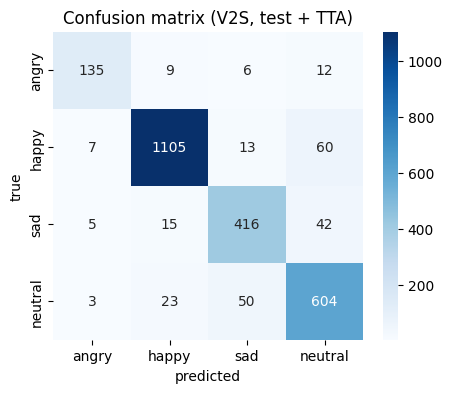

In [16]:
# --- Section 8: Test evaluation + TTA + confusion matrix ---
test_loss, test_acc = model.evaluate(test_ds, verbose=0)
print("Plain test accuracy:", round(test_acc, 4))

p1 = model.predict(test_ds, verbose=0)
p2 = model.predict(test_ds.map(lambda x, y: (tf.image.flip_left_right(x), y)), verbose=0)   # TTA
proba  = (p1 + p2) / 2
y_pred = proba.argmax(1)
y_true = np.concatenate([y.numpy() for _, y in test_ds], axis=0)
print("TTA test accuracy:", round((y_pred == y_true).mean(), 4))

print(classification_report(y_true, y_pred, target_names=TARGET_CLASSES))
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=TARGET_CLASSES,
            yticklabels=TARGET_CLASSES, cmap='Blues')
plt.xlabel('predicted'); plt.ylabel('true'); plt.title('Confusion matrix (V2S, test + TTA)'); plt.show()

In [17]:
# --- Section 9: Save the trained model ---
model.save('emotion_classifier_rafdb.keras')
print("✓ Saved as emotion_classifier_rafdb.keras")

✓ Saved as emotion_classifier_rafdb.keras


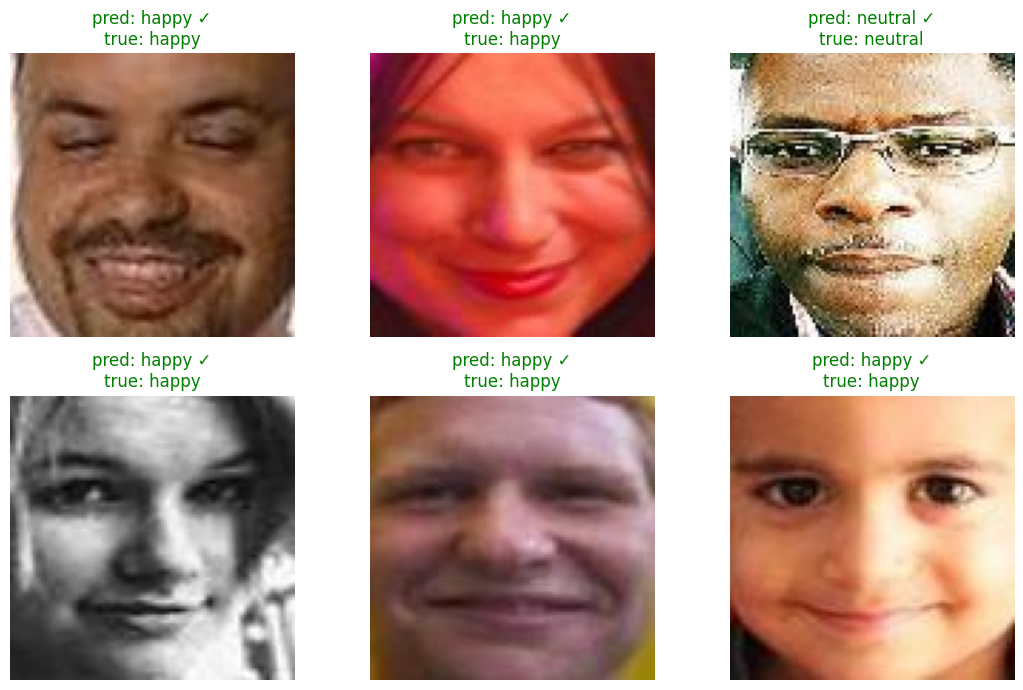

In [20]:
# --- Section 10: Production inference function ---
from PIL import Image
CLASS_NAMES = ['angry', 'happy', 'sad', 'neutral']

def predict_emotion(image_path, use_tta=True):
    """Production predict: load image -> same preprocessing as training -> emotion + probs."""
    img = np.array(Image.open(image_path).convert('RGB'))
    img = tf.cast(tf.image.resize(img, [IMG_SIZE, IMG_SIZE]), tf.uint8).numpy()
    x = clahe_rgb(img).astype('float32')[None, ...]           # same CLAHE as training
    p = model.predict(x, verbose=0)
    if use_tta:
        p = (p + model.predict(x[:, :, ::-1, :], verbose=0)) / 2   # TTA
    probs = p[0]
    return CLASS_NAMES[int(probs.argmax())], {CLASS_NAMES[i]: round(float(probs[i]), 3) for i in range(4)}

# Demo on 6 unseen test images
import random
fig, axes = plt.subplots(2, 3, figsize=(11, 7))
for ax, i in zip(axes.ravel(), random.sample(range(len(test_paths)), 6)):
    label, probs = predict_emotion(test_paths[i])
    true = CLASS_NAMES[test_labels[i]]; ok = (label == true)
    ax.imshow(Image.open(test_paths[i])); ax.axis('off')
    ax.set_title(f"pred: {label} {'✓' if ok else '✗'}\ntrue: {true}", color='green' if ok else 'red')
plt.tight_layout(); plt.show()

## Conclusions

Production emotion classifier (Angry / Happy / Sad / Neutral) on RAF-DB using
transfer learning (EfficientNetV2S) with a professional preprocessing pipeline.

**Result: 90.2% test accuracy** (with TTA), macro-F1 0.88 — at the RAF-DB research frontier.

Pipeline: RAF-DB (clean labels) -> resize + CLAHE lighting normalization -> augmentation
-> EfficientNetV2S (transfer learning, 2-phase fine-tuning) -> class weights for imbalance
-> mixed-precision training -> TTA at inference.

Key learnings: data quality (RAF-DB vs noisy FER) and model capacity (V2S vs B0) drove
the gains; real-world emotion recognition honestly tops out ~90% due to label ambiguity.